<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week10/%EC%A3%BC%EA%B0%80_RNN_LSTM_%EA%B3%B5%EC%A0%95%ED%95%9C_%EB%B0%A9%EC%8B%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 삼성전자 주가 예측: SimpleRNN vs LSTM (80:20 분리 / Data Leakage 방지)
교수님이 제시한 학습 80%, 테스트 20% 분리 방식을 반영했습니다. 각 구간에서 독립적으로 Window를 생성하고, 정규화는 학습 데이터로만 학습합니다.


In [1]:
!pip -q install finance-datareader

In [2]:
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)
WINDOW_SIZE = 30
TRAIN_RATIO = 0.8
EPOCHS = 50
BATCH_SIZE = 8


## 1. 주가 데이터 불러오기 및 Open 열 확인

In [3]:
df = fdr.DataReader('005930', '2016')
print('전체 데이터:', df.shape)
print(df.head())
open_values = df[['Open']].dropna()
print('\n시가(Open) 데이터:')
print(open_values.head())

전체 데이터: (2660, 6)
             Open   High    Low  Close  Volume    Change
Date                                                    
2016-01-04  25200  25200  24100  24100  306939 -0.043651
2016-01-05  24040  24360  23720  24160  216002  0.002490
2016-01-06  24160  24160  23360  23500  366752 -0.027318
2016-01-07  23320  23660  23020  23260  282388 -0.010213
2016-01-08  23260  23720  23260  23420  257763  0.006879

시가(Open) 데이터:
             Open
Date             
2016-01-04  25200
2016-01-05  24040
2016-01-06  24160
2016-01-07  23320
2016-01-08  23260


## 2. 시간 순서대로 80:20 분리 → 학습 데이터 기준 정규화
전체 데이터에 `fit_transform`을 적용하면 테스트 구간의 최솟값·최댓값이 학습 전처리에 반영됩니다. 먼저 분리한 후 학습 구간에만 `fit`을 수행합니다.


In [4]:
data = open_values.values
split = int(len(data) * TRAIN_RATIO)
train_raw = data[:split]
test_raw = data[split:]

scaler = MinMaxScaler(feature_range=(0, 1))
train_data = scaler.fit_transform(train_raw)
test_data = scaler.transform(test_raw)

print('전체 데이터:', data.shape)
print('학습 원본:', train_raw.shape, '테스트 원본:', test_raw.shape)
print('정규화 전 Open (처음 5개):', train_raw[:5].ravel())
print('정규화 후 Open (처음 5개):', train_data[:5].ravel())
print('테스트 데이터 정규화 값 (처음 5개):', test_data[:5].ravel())


전체 데이터: (2660, 1)
학습 원본: (2128, 1) 테스트 원본: (532, 1)
정규화 전 Open (처음 5개): [25200 24040 24160 23320 23260]
정규화 후 Open (처음 5개): [0.27906977 0.2662237  0.2675526  0.25825028 0.25758583]
테스트 데이터 정규화 값 (처음 5개): [0.83942414 0.81506091 0.82392027 0.82502769 0.82059801]


## 3. Window Size에 맞춰 시퀀스 생성

In [5]:
def make_sample(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i+window])
        y.append(data[i+window])
    return np.array(X), np.array(y)

# 교수님이 제시한 방식: 각 구간 내부에서 별도로 Window 생성
X_train, y_train = make_sample(train_data, WINDOW_SIZE)
X_test, y_test = make_sample(test_data, WINDOW_SIZE)

print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_test:', X_test.shape, 'y_test:', y_test.shape)
print('첫 입력 샘플 (앞 5개):', X_train[0, :5, 0])
print('첫 정답:', y_train[0, 0])


X_train: (2098, 30, 1) y_train: (2098, 1)
X_test: (502, 30, 1) y_test: (502, 1)
첫 입력 샘플 (앞 5개): [0.27906977 0.2662237  0.2675526  0.25825028 0.25758583]
첫 정답: 0.2664451827242525


## 4. SimpleRNN 모델 구성 및 학습

In [6]:
rnn_model = tf.keras.Sequential([
    tf.keras.Input(shape=(WINDOW_SIZE, 1)),
    tf.keras.layers.SimpleRNN(64, return_sequences=True),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1)
])
rnn_model.compile(optimizer='adam', loss='mse')
rnn_model.summary()
rnn_history = rnn_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1, shuffle=False)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 30, 64)         │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,361 (28.75 KB)

 Trainable params: 7,361 (28.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.0044
Epoch 2/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0058
Epoch 3/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0068
Epoch 4/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0065
Epoch 5/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0058
Epoch 6/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0055
Epoch 7/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0051
Epoch 8/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0047
Epoch 9/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0044
Epoch 10/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0044
Epoch 11/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0038
Epoch 12/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0036
Epoch 13/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0032
Epoch 14/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0030
Epoch 15/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - 

## 5. LSTM 모델 구성 및 학습

In [7]:
lstm_model = tf.keras.Sequential([
    tf.keras.Input(shape=(WINDOW_SIZE, 1)),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.summary()
lstm_history = lstm_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1, shuffle=False)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0020
Epoch 2/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0014
Epoch 3/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0015
Epoch 4/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0016
Epoch 5/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0017
Epoch 6/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0018
Epoch 7/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0018
Epoch 8/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0018
Epoch 9/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0018
Epoch 10/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0018
Epoch 11/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0017
Epoch 12/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0017
Epoch 13/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0017
Epoch 14/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0016
Epoch 15/50
263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - lo

## 6. 테스트 구간 예측 및 원화 단위 복원

In [8]:
rnn_pred = scaler.inverse_transform(rnn_model.predict(X_test))
lstm_pred = scaler.inverse_transform(lstm_model.predict(X_test))
actual = scaler.inverse_transform(y_test)

# 테스트 구간의 첫 WINDOW_SIZE일은 입력으로만 사용하므로 날짜도 제외
prediction_dates = open_values.index[split + WINDOW_SIZE:]
print(pd.DataFrame({
    'Actual_Open': actual.ravel(),
    'RNN_Pred': rnn_pred.ravel(),
    'LSTM_Pred': lstm_pred.ravel()
}, index=prediction_dates).head(10))


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
            Actual_Open      RNN_Pred     LSTM_Pred
Date                                               
2024-10-17      59400.0  72120.625000  61552.746094
2024-10-18      59900.0  71471.593750  61413.613281
2024-10-21      59000.0  72325.101562  62051.363281
2024-10-22      58800.0  71715.976562  61238.140625
2024-10-23      57500.0  71145.726562  60995.269531
2024-10-24      58200.0  70753.312500  59790.402344
2024-10-25      56000.0  71011.742188  60493.535156
2024-10-28      55700.0  69565.265625  58445.125000
2024-10-29      58000.0  69087.609375  58050.515625
2024-10-30      59100.0  71152.140625  60480.324219


## 7. 평가 지표 출력 (원화 기준)

In [9]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE (KRW)': mean_absolute_error(y_true, y_pred), 'MSE (KRW^2)': mse, 'RMSE (KRW)': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

results = pd.DataFrame({'SimpleRNN': metrics(actual, rnn_pred), 'LSTM': metrics(actual, lstm_pred)}).T
print(results.round(4))

            MAE (KRW)   MSE (KRW^2)  RMSE (KRW)      R2
SimpleRNN  64159.1302  9.054743e+09  95156.4109 -0.0924
LSTM       17009.3276  7.863105e+08  28041.2290  0.9051


## 8. 실제 주가와 예측 주가 비교

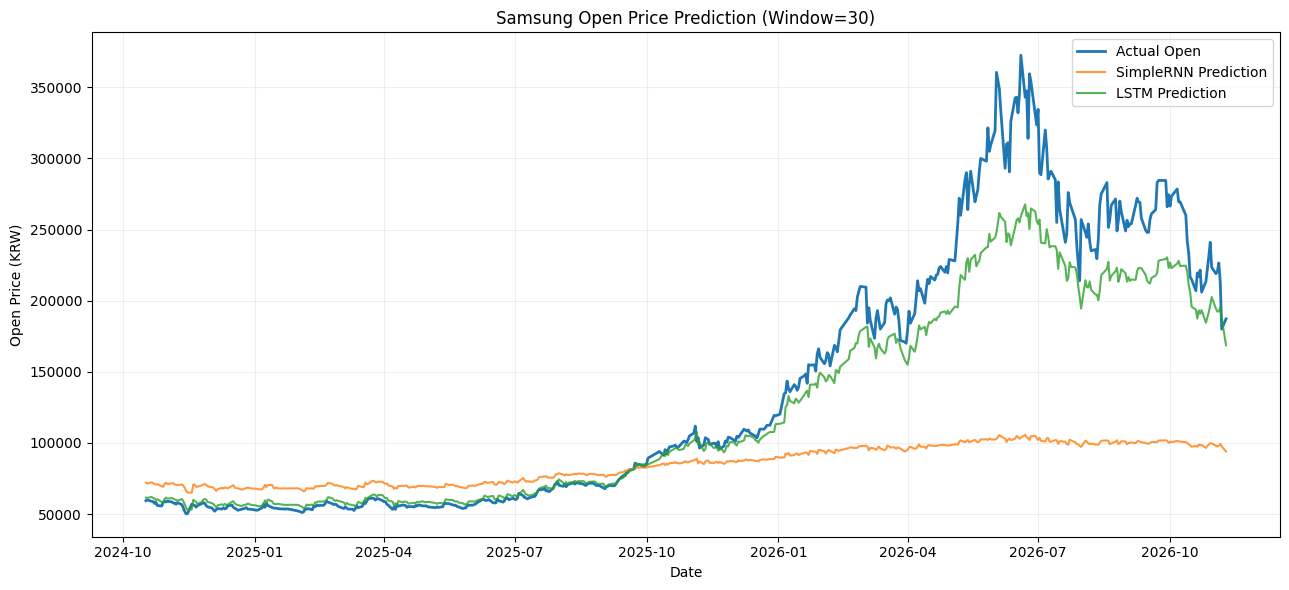

In [10]:
plt.figure(figsize=(13, 6))
plt.plot(prediction_dates, actual.ravel(), label='Actual Open', linewidth=2)
plt.plot(prediction_dates, rnn_pred.ravel(), label='SimpleRNN Prediction', alpha=.8)
plt.plot(prediction_dates, lstm_pred.ravel(), label='LSTM Prediction', alpha=.8)
plt.title(f'Samsung Open Price Prediction (Window={WINDOW_SIZE})')
plt.xlabel('Date')
plt.ylabel('Open Price (KRW)')
plt.legend()
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()
